# Ingestão e análise - Antecipação de Recebíveis da Olist

O objetivo desse mini-projeto é aplicar os conceitos de **Engenharia e Análise de Dados** para estudo e construção de portfólio.\
Abaixo um pipeline de dados (camadas **bronze → silver → gold**) foi montado completamente usando os recursos do Databricks com scripts em **Python, PySpark e SQL**.\
\
**Dataset utilizado**: Kaggle -  [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)

## 3. Regras de negócio

Não são premissas de mercado (taxas, MDR, custo de captação de dinheiro): são regras de construção da agenda e cortes da segmentação. Ficam aqui para que nenhum número apareça "solto" no código.

In [0]:
# Agenda: a parcela k de uma venda no crédito liquida em D + 30·k.
PRAZO_DIAS_PARCELA = 30

# Segmentação por regra (Etapa 3). Ajuste depois de olhar as distribuições e registre o motivo.
SEG_TOP_AGENDA = 0.20 # top 20% dos lojistas por agenda em aberto
SEG_MIN_PARCELADO = 0.50 # > 50% do TPV no crédito parcelado = "grande parcelador"
SEG_MAX_PARCELADO_AVISTA = 0.20 # < 20% do TPV parcelado = "à vista"
SEG_MIN_MESES_ATIVOS = 3 # vendas em pelo menos 3 meses...
SEG_JANELA_MESES = 6 # ...dos últimos 6 meses até a data de corte
# 5º segmento, aberto após o k-means (seção 6.6 do notebook 06) mostrar que "Pequenos ou
# esporádicos" misturava dois perfis: o cluster "prazo longo · ticket alto" tem venda grande,
# parcelada e com espera longa (~4 meses), mas sem recorrência — não merece o rótulo "pequeno".
SEG_MIN_PRAZO_OCASIONAIS = 90 # prazo médio contratado >= 90 dias (~3+ parcelas) = "grande ocasional"

# K-means
KMEANS_MIN_PEDIDOS = 3 # lojistas com menos pedidos geram ruído no agrupamento
KMEANS_K_RANGE = range(2, 9)
KMEANS_SEED = 42


## View de parâmetros para as células SQL

As células `%sql` leem os parâmetros desta view temporária (`CROSS JOIN params`).

In [0]:
spark.sql(f"""
CREATE OR REPLACE TEMP VIEW params AS
SELECT
  DATE('2018-06-30') AS data_corte,
  {PRAZO_DIAS_PARCELA} AS prazo_dias,
  {SEG_TOP_AGENDA} AS seg_top_agenda,
  {SEG_MIN_PARCELADO} AS seg_min_parcelado,
  {SEG_MAX_PARCELADO_AVISTA} AS seg_max_parcelado_avista,
  {SEG_MIN_MESES_ATIVOS} AS seg_min_meses_ativos,
  {SEG_JANELA_MESES} AS seg_janela_meses,
  {SEG_MIN_PRAZO_OCASIONAIS} AS seg_min_prazo_ocasionais
""")

DataFrame[]

## 4. Gold - agenda de recebíveis
Cada venda no cartão de crédito é "explodida" em parcelas com data de liquidação. A parcela *k* de uma venda em *n* vezes liquida em **D0 + 30·k** dias (D0 = data de aprovação).
Tabelas geradas:
| Tabela | Grão | Para que serve |
| --- | --- | --- |
| `f_agenda` | parcela | Agenda completa, base de tudo |
| `agenda_aberta_seller` | lojista | Agenda em aberto na data de corte: o que o lojista poderia antecipar |
| `agenda_aberta_vencimento` | lojista × mês de vencimento | Concentração da agenda no tempo |
| `agenda_snapshot_mensal` | fim de mês × lojista | Evolução da agenda em aberto ao longo da série |
Valores são **brutos** (sem MDR): o objetivo desta etapa é medir o tamanho e o prazo da agenda, não a receita.

In [0]:
from datetime import date

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

#### 4.1. `f_agenda`

Entram só vendas no crédito, não canceladas e com valor positivo. O valor de cada parcela é o valor da venda dividido igualmente pelo número de parcelas.

In [0]:
%sql
CREATE OR REPLACE TABLE workspace.olist.gold_f_agenda AS
SELECT
  v.order_id,
  v.payment_sequential,
  v.seller_id,
  v.categoria,
  v.data_venda,
  v.parcelas,
  t.n_parcela,
  v.valor_venda / v.parcelas AS valor_parcela,
  date_add(v.data_venda, p.prazo_dias * t.n_parcela) AS data_liquidacao
FROM workspace.olist.silver_f_venda_seller v
CROSS JOIN params p
LATERAL VIEW explode(sequence(1, v.parcelas)) t AS n_parcela
WHERE v.payment_type = 'credit_card'
  AND NOT v.flag_cancelado
  AND v.valor_venda > 0

num_affected_rows,num_inserted_rows


#### 4.2. Agenda em aberto na data de corte, por lojista

"Em aberto" = parcelas de vendas feitas até a data de corte que ainda não liquidaram nessa data. É o estoque que o lojista poderia antecipar.

**Prazo médio ponderado** = Σ (valor × dias até liquidar) ÷ Σ valor. Diz quanto tempo, em média, cada real da agenda ainda leva para cair na conta.

In [0]:
%sql
CREATE OR REPLACE TABLE workspace.olist.gold_agenda_aberta_seller AS
SELECT
  a.seller_id,
  p.data_corte,
  sum(a.valor_parcela) AS agenda_aberta,
  count(*) AS parcelas_futuras,
  count(DISTINCT a.order_id) AS vendas_com_saldo,
  sum(a.valor_parcela * datediff(a.data_liquidacao, p.data_corte))
    / sum(a.valor_parcela) AS prazo_medio_dias,
  max(a.data_liquidacao) AS ultima_liquidacao
FROM workspace.olist.gold_f_agenda a
CROSS JOIN params p
WHERE a.data_venda <= p.data_corte
  AND a.data_liquidacao > p.data_corte
GROUP BY a.seller_id, p.data_corte

num_affected_rows,num_inserted_rows


In [0]:
%sql
CREATE OR REPLACE TABLE workspace.olist.gold_agenda_aberta_vencimento AS
SELECT
  a.seller_id,
  trunc(a.data_liquidacao, 'MM') AS mes_vencimento,
  CAST(months_between(trunc(a.data_liquidacao, 'MM'),
                      trunc(p.data_corte, 'MM')) AS INT) AS meses_a_frente,
  sum(a.valor_parcela) AS valor_aberto
FROM workspace.olist.gold_f_agenda a
CROSS JOIN params p
WHERE a.data_venda <= p.data_corte
  AND a.data_liquidacao > p.data_corte
GROUP BY a.seller_id, trunc(a.data_liquidacao, 'MM'), p.data_corte

num_affected_rows,num_inserted_rows


#### Quando a agenda em aberto vence?

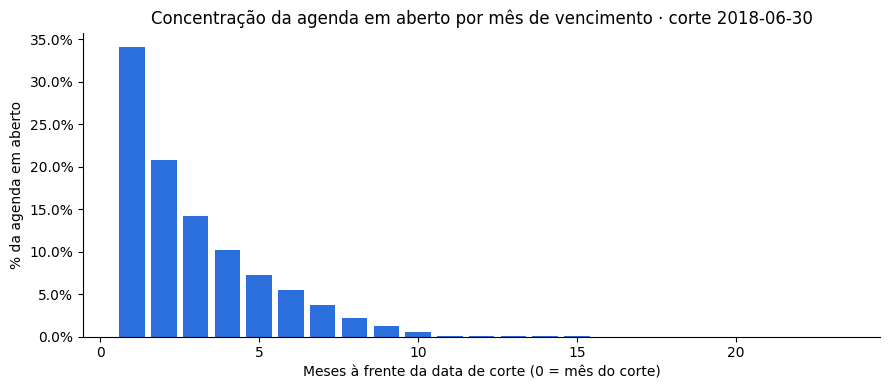

meses_a_frente,valor,pct,pct_acum
1,828510.2566890691,0.34054964613447747,0.34054964613447747
2,504970.33792816754,0.20756227035386296,0.5481119164883405
3,345754.9546799693,0.14211861170681306,0.6902305281951535
4,247658.92275810448,0.10179736198361913,0.7920278901787726
5,176072.78305731463,0.07237269964973292,0.8644005898285055
6,132967.5272831445,0.05465477825779675,0.9190553680863023
7,91545.14556078332,0.03762858295881529,0.9566839510451176
8,53757.94580086288,0.022096587545651573,0.9787805385907692
9,29730.67583188736,0.012220453581768776,0.991000992172538
10,13085.3007799948,0.0053785629257005,0.9963795550982385


In [0]:
venc = spark.sql("""
  SELECT meses_a_frente, sum(valor_aberto) AS valor
  FROM workspace.olist.gold_agenda_aberta_vencimento
  GROUP BY meses_a_frente
  ORDER BY meses_a_frente
""").toPandas()
venc["pct"] = venc["valor"] / venc["valor"].sum()
venc["pct_acum"] = venc["pct"].cumsum()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(venc["meses_a_frente"], venc["pct"], color="#2a6fdb")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Meses à frente da data de corte (0 = mês do corte)")
ax.set_ylabel("% da agenda em aberto")
ax.set_title(f"Concentração da agenda em aberto por mês de vencimento · corte 2018-06-30")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

display(venc)

#### 4.3. Snapshot mensal da agenda em aberto

Repete o corte no último dia de cada mês da série. Mostra se a agenda cresce junto com as vendas e se o prazo médio muda com o tempo. Os primeiros e os últimos meses da Olist têm poucas vendas; leia as pontas com cuidado.

In [0]:
%sql
CREATE OR REPLACE TABLE workspace.olist.gold_agenda_snapshot_mensal AS
WITH limites AS (
  SELECT trunc(min(data_venda), 'MM') AS ini, trunc(max(data_venda), 'MM') AS fim
  FROM workspace.olist.gold_f_agenda
),
meses AS (
  SELECT last_day(m) AS data_ref
  FROM limites
  LATERAL VIEW explode(sequence(ini, fim, INTERVAL 1 MONTH)) t AS m
)
SELECT
  m.data_ref,
  a.seller_id,
  sum(a.valor_parcela) AS agenda_aberta,
  sum(a.valor_parcela * datediff(a.data_liquidacao, m.data_ref))
    / sum(a.valor_parcela) AS prazo_medio_dias
FROM meses m
JOIN workspace.olist.gold_f_agenda a
  ON a.data_venda <= m.data_ref
 AND a.data_liquidacao > m.data_ref
GROUP BY m.data_ref, a.seller_id

num_affected_rows,num_inserted_rows


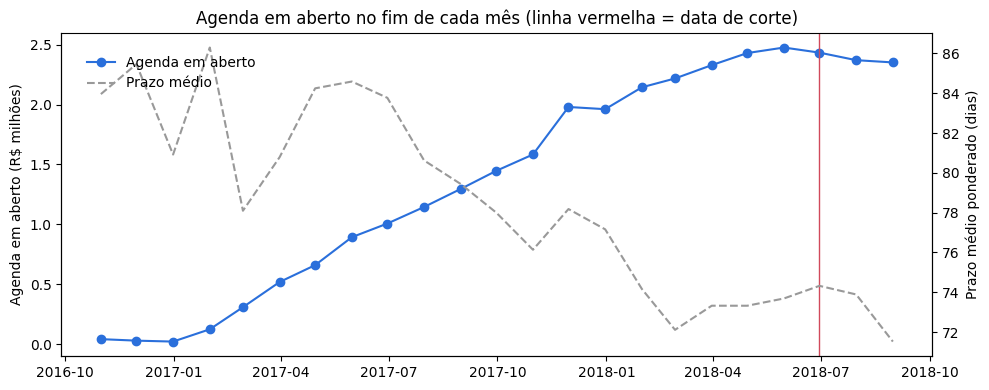

data_ref,agenda_aberta,prazo_medio_dias,lojistas_com_agenda
2016-10-31,43572.340000000004,83.9585585717912,116
2016-11-30,31022.783916666678,85.46403002608751,95
2016-12-31,23274.077833333336,80.92164254357385,90
2017-01-31,125718.87174999996,86.2981073280311,228
2017-02-28,310107.7644722223,78.097650781275,437
2017-03-31,520171.14475052984,80.79113150592777,573
2017-04-30,660897.2707510614,84.24751244903753,640
2017-05-31,893807.7557833375,84.5902439635955,727
2017-06-30,1007671.3661752823,83.77056715158683,771
2017-07-31,1145658.2777122206,80.62556313080202,857


In [0]:
serie = spark.sql("""
  SELECT data_ref,
         sum(agenda_aberta)                                       AS agenda_aberta,
         sum(agenda_aberta * prazo_medio_dias) / sum(agenda_aberta) AS prazo_medio_dias,
         count(DISTINCT seller_id)                                AS lojistas_com_agenda
  FROM workspace.olist.gold_agenda_snapshot_mensal
  GROUP BY data_ref
  ORDER BY data_ref
""").toPandas()

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(serie["data_ref"], serie["agenda_aberta"] / 1e6, color="#2a6fdb", marker="o", label="Agenda em aberto")
ax1.set_ylabel("Agenda em aberto (R$ milhões)")
ax2 = ax1.twinx()
ax2.plot(serie["data_ref"], serie["prazo_medio_dias"], color="#999999", linestyle="--", label="Prazo médio")
ax2.set_ylabel("Prazo médio ponderado (dias)")
ax1.axvline(date.fromisoformat('2018-06-30'), color="#d1495b", linewidth=1)
ax1.set_title("Agenda em aberto no fim de cada mês (linha vermelha = data de corte)")
ax1.spines[["top"]].set_visible(False)
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.88), frameon=False)
plt.tight_layout()
plt.show()

display(serie)